# Examen Práctico — Primer Parcial
## Tópicos de Big Data

**Instrucciones generales**

- Este notebook es tu entregable. Complétalo en orden, sin borrar los enunciados.
- Al final debes subir este archivo (`.ipynb`) al repositorio de GitHub del curso, en la carpeta correspondiente a tu nombre/usuario.
- Se evaluará tanto el código (que corra sin errores, de arriba hacia abajo) como tus interpretaciones escritas en las celdas de texto marcadas como *"Interpretación"*.
- Cada quien trabaja con **un dataset distinto**, asignado por la profesora. No copies celdas de un compañero con un dataset diferente: aunque las preguntas se parecen, los datos y las columnas no son las mismas.


## 0. Datos del alumno

Completa la siguiente celda con tus datos y el nombre del dataset que te fue asignado.

In [2]:
# --- COMPLETA CON TUS DATOS ---
NOMBRE = "Luis Gerardo Ruiz Torres"            # Tu nombre completo
MATRICULA = "82046"         # Tu matrícula o número de cuenta
DATASET_ASIGNADO = "alcohol"  # Debe ser uno de: "alcohol", "migracion", "desnutricion", "pib", "homicidios"

print(f"Alumno: {NOMBRE}")
print(f"Matrícula: {MATRICULA}")
print(f"Dataset asignado: {DATASET_ASIGNADO}")


Alumno: Luis Gerardo Ruiz Torres
Matrícula: 82046
Dataset asignado: alcohol


## 1. Configuración del entorno virtual (Visual Studio Code)

Antes de instalar librerías directamente en tu sistema, es una buena práctica crear un
**entorno virtual** exclusivo para este examen. Esto evita conflictos de versiones con
otros proyectos y hace que tu entorno de trabajo sea reproducible.

**Requisitos previos en VS Code:** ten instaladas las extensiones oficiales **"Python"**
y **"Jupyter"** (ambas de Microsoft), disponibles en la pestaña de Extensiones (ícono de
cuadritos en la barra lateral izquierda, o `Ctrl+Shift+X` / `Cmd+Shift+X`).

Abre una terminal **dentro de VS Code** (menú **Terminal → New Terminal**, o
`` Ctrl+ñ ``/`` Ctrl+` ``) y verifica que estés ubicado en la carpeta de tu repositorio
del curso (donde vas a guardar este notebook).

### Windows (PowerShell, terminal integrada de VS Code)

```powershell
# 1. Crear el entorno virtual (se creará una carpeta llamada ".venv")
python -m venv .venv

# 2. Activar el entorno virtual
.venv\Scripts\Activate.ps1

# Si PowerShell bloquea la ejecución de scripts, ejecuta una sola vez:
#   Set-ExecutionPolicy -Scope CurrentUser RemoteSigned
# y vuelve a intentar activar el entorno.

# 3. Instalar las librerías necesarias
pip install pandas numpy ipykernel matplotlib requests
```

### macOS / Linux (terminal integrada de VS Code, bash o zsh)

```bash
# 1. Crear el entorno virtual (se creará una carpeta llamada ".venv")
python3 -m venv .venv

# 2. Activar el entorno virtual
source .venv/bin/activate

# 3. Instalar las librerías necesarias
pip install pandas numpy ipykernel matplotlib requests
```

> **Nota:** usamos el nombre `.venv` (con punto) porque VS Code lo detecta automáticamente
> dentro de la carpeta del proyecto. Si usas Anaconda/Miniconda en lugar de `venv`, el
> equivalente es:
> ```bash
> conda create -n examen-bigdata python=3.11 pandas numpy ipykernel matplotlib requests -y
> conda activate examen-bigdata
> ```

### Seleccionar el entorno virtual como kernel en VS Code

A diferencia de Jupyter Notebook/Lab, en VS Code **no necesitas registrar el entorno
manualmente con `ipykernel install`**: basta con tener el paquete `ipykernel` instalado
en el entorno (ya quedó instalado en el paso anterior) y seleccionar ese entorno
directamente como kernel del notebook.

1. Abre este archivo `.ipynb` en VS Code.
2. En la esquina superior derecha del notebook, haz clic en el selector de kernel
   (dice algo como **"Select Kernel"** la primera vez).
3. Elige **"Python Environments..."** y de la lista selecciona el entorno `.venv`
   que acabas de crear (debe aparecer como algo como `.venv (Python 3.x.x)` con la
   ruta de tu proyecto).
4. Si no aparece en la lista, haz clic en **"Select Another Kernel" → "Python
   Environments..."** y usa **"Enter interpreter path..."** para localizar manualmente
   el ejecutable dentro de `.venv/bin/python` (macOS/Linux) o `.venv\Scripts\python.exe`
   (Windows).
5. Verifica que quedó bien seleccionado ejecutando la celda de abajo: debe mostrar una
   ruta que contenga la carpeta `.venv` (o el nombre de tu entorno de conda), y no la
   instalación global de Python.

In [3]:
import sys
print(sys.executable)
# Debe mostrar una ruta dentro de tu carpeta "venv" (o de tu entorno "examen-bigdata" si usas conda).
# Si muestra la ruta de tu instalacion global de Python, regresa al paso anterior
# y selecciona el kernel correcto antes de continuar.


c:\Users\ruizt\Quinto Semestre\Topicos BigData\Examen Parcial 1\.venv\Scripts\python.exe


## 2. Configuración y carga de datos

La siguiente celda **no se modifica**. Contiene la configuración de los 5 datasets
posibles del examen. A partir de tu variable `DATASET_ASIGNADO` de la celda anterior,
el notebook cargará automáticamente el dataset y los metadatos que te corresponden.

In [4]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import requests

# --- NO MODIFICAR: configuración de los 5 datasets del examen ---
DATASETS = {
    "alcohol": {
        "csv": "https://ourworldindata.org/grapher/share-of-adults-who-drank-alcohol-in-last-year.csv?v=1&csvType=full&useColumnShortNames=true",
        "meta": "https://ourworldindata.org/grapher/share-of-adults-who-drank-alcohol-in-last-year.metadata.json?v=1&csvType=full&useColumnShortNames=true",
        "valor_col": "alcohol__consumers_past_12_months__pct__age_standardized__sex_both_sexes",
        "filtro_paises": "code",       # columna a usar para filtrar países reales vs. agregados
        "descripcion": "Porcentaje de adultos (15+) que bebieron alcohol en el ultimo anio",
        "unidad": "%",
    },
    "migracion": {
        "csv": "https://ourworldindata.org/grapher/migrant-populations.csv?v=1&csvType=full&useColumnShortNames=true&metric=immigrants&unit=number",
        "meta": "https://ourworldindata.org/grapher/migrant-populations.metadata.json?v=1&csvType=full&useColumnShortNames=true&metric=immigrants&unit=number",
        "valor_col": "immigrants_all",
        "filtro_paises": "owid_region",
        "descripcion": "Numero total de inmigrantes internacionales residiendo en el pais",
        "unidad": "personas",
    },
    "desnutricion": {
        "csv": "https://ourworldindata.org/grapher/number-undernourished.csv?v=1&csvType=full&useColumnShortNames=true",
        "meta": "https://ourworldindata.org/grapher/number-undernourished.metadata.json?v=1&csvType=full&useColumnShortNames=true",
        "valor_col": "_2_1_1_number_of_undernourished_people__000000000024001__value__006132__millions",
        "filtro_paises": "code",
        "descripcion": "Numero de personas subalimentadas (desnutricion)",
        "unidad": "personas",
    },
    "pib": {
        "csv": "https://ourworldindata.org/grapher/gdp-per-capita-worldbank-constant-usd.csv?v=1&csvType=full&useColumnShortNames=true",
        "meta": "https://ourworldindata.org/grapher/gdp-per-capita-worldbank-constant-usd.metadata.json?v=1&csvType=full&useColumnShortNames=true",
        "valor_col": "ny_gdp_pcap_kd",
        "filtro_paises": "code",
        "descripcion": "PIB per capita (dolares constantes de 2015)",
        "unidad": "USD",
    },
    "homicidios": {
        "csv": "https://ourworldindata.org/grapher/homicides-unodc.csv?v=1&csvType=full&useColumnShortNames=true",
        "meta": "https://ourworldindata.org/grapher/homicides-unodc.metadata.json?v=1&csvType=full&useColumnShortNames=true",
        "valor_col": "value__category_total__sex_total__age_total__unit_of_measurement_counts",
        "filtro_paises": "owid_region",
        "descripcion": "Numero de homicidios intencionales por anio",
        "unidad": "homicidios",
    },
}

assert DATASET_ASIGNADO in DATASETS, (
    "DATASET_ASIGNADO debe ser uno de: " + ", ".join(DATASETS.keys())
)

config = DATASETS[DATASET_ASIGNADO]
print(f"Cargando dataset: {DATASET_ASIGNADO}")
print(f"Descripcion: {config['descripcion']} ({config['unidad']})")


Cargando dataset: alcohol
Descripcion: Porcentaje de adultos (15+) que bebieron alcohol en el ultimo anio (%)


In [5]:
# Carga de datos y metadatos desde Our World in Data
df = pd.read_csv(
    config["csv"],
    storage_options={'User-Agent': 'Our World In Data data fetch/1.0'}
)
metadata = requests.get(config["meta"]).json()

# Renombramos la columna de valor a "valor" para trabajar mas comodo durante todo el notebook
df = df.rename(columns={config["valor_col"]: "valor"})


In [6]:
df.head(25)

,entity,code,year,valor
0,Afghanistan,AFG,2000,2.034725
1,Afghanistan,AFG,2001,2.032329
2,Afghanistan,AFG,2002,2.033833
3,Afghanistan,AFG,2003,2.034417
4,Afghanistan,AFG,2004,2.035337
5,Afghanistan,AFG,2005,2.034475
6,Afghanistan,AFG,2006,2.038559
7,Afghanistan,AFG,2007,2.029229
8,Afghanistan,AFG,2008,2.022360
9,Afghanistan,AFG,2009,2.018910


## 3. Exploración inicial

Antes de responder las preguntas de análisis, explora el dataset: tipos de datos,
dimensiones, valores nulos y estadísticas descriptivas básicas.

In [7]:
# Forma del dataset (filas, columnas)
df.shape


(3929, 4)

In [8]:
# Tipos de datos e informacion general
df.info()


<class 'pandas.DataFrame'>
RangeIndex: 3929 entries, 0 to 3928
Data columns (total 4 columns):
 #   Column  Non-Null Count  Dtype  
---  ------  --------------  -----  
 0   entity  3929 non-null   str    
 1   code    3929 non-null   str    
 2   year    3929 non-null   int64  
 3   valor   3929 non-null   float64
dtypes: float64(1), int64(1), str(2)
memory usage: 122.9 KB


In [9]:
# Estadisticas descriptivas de la columna 'valor'
df['valor'].describe()


count    3929.000000
mean       42.460783
std        24.126328
min         0.830784
25%        24.925045
50%        42.829540
75%        62.844517
max        85.056270
Name: valor, dtype: float64

In [10]:
# Conteo de valores nulos por columna
df.isnull().sum()


entity    0
code      0
year      0
valor     0
dtype: int64

**Interpretación (2-3 líneas):** ¿qué observas sobre los valores nulos, el rango de
años y el tipo de variable con la que vas a trabajar?

*(Escribe aquí tu respuesta)*
El conjunto de datos está completamente limpio, ya que no presenta valores nulos en ninguna de sus 3,929 filas. Se trabajará con una variable principal de tipo numérico continuo

## 4. Preguntas de análisis

A continuación responde las 10 preguntas. 

Cada una tiene una celda de código para su solución y, cuando aplica, 
una celda de texto para tu interpretación. Recuerda que tu
dataset (`DATASET_ASIGNADO`) puede o no tener la columna `owid_region`; revisa el
diccionario `DATASETS` de la celda de configuración para saber qué columna (`code` u
`owid_region`) te toca usar para distinguir países reales de agregados (continentes,
"World", grupos de ingreso, etc.).

### Pregunta 1 — Filtrado de países reales y ranking

Filtra el DataFrame para quedarte solo con países reales (usa la columna indicada en `config['filtro_paises']` de tu dataset). Guarda el resultado en una nueva variable `df_paises`. ¿Cuántos países distintos hay? Muestra los 10 países con mayor valor y los 10 con menor valor.

In [11]:
# Pregunta 1
# Tu codigo aqui
# Filtro
col_filtro = config['filtro_paises']
df_paises = df[df[col_filtro].notna()].copy()

#Paises distintos
num_paises_distintos = df_paises['entity'].nunique()
print(f"Hay {num_paises_distintos} países distintos en el dataset.\n")

#10 mayores
top_10_mayor = df_paises.nlargest(10, 'valor')
print("--- 10 registros con mayor valor ---")
display(top_10_mayor[['entity', 'year', 'valor']])

#10 Menores
top_10_menor = df_paises.nsmallest(10, 'valor')
print("\n--- 10 registros con menor valor ---")
display(top_10_menor[['entity', 'year', 'valor']])

Hay 189 países distintos en el dataset.

--- 10 registros con mayor valor ---


,entity,year,valor
69,Andorra,2006,85.056270
68,Andorra,2005,84.885210
70,Andorra,2007,84.741150
64,Andorra,2001,84.728065
67,Andorra,2004,84.604740
2117,Luxembourg,2017,84.553620
2119,Luxembourg,2019,84.505740
2118,Luxembourg,2018,84.496760
2116,Luxembourg,2016,84.465840
66,Andorra,2003,84.429360



--- 10 registros con menor valor ---


,entity,year,valor
1931,Kuwait,2020,0.830784
1927,Kuwait,2016,0.859087
779,Comoros,2002,0.868431
778,Comoros,2001,0.871331
777,Comoros,2000,0.872753
784,Comoros,2007,0.886865
785,Comoros,2008,0.887536
1926,Kuwait,2015,0.893008
787,Comoros,2010,0.895492
788,Comoros,2011,0.896825


**Interpretación:**

*(Escribe aquí tu respuesta)*

Tras filtrar el dataset para conservar únicamente los países reales, se identificó un total de 189 países distintos. Al analizar los extremos de la muestra, se observa que Andorra y Luxemburgo concentran los registros con los valores más altos rondando los 84 y 85, mientras que Kuwait y Comoras presentan los niveles más bajos del indicador todos por debajo de 0.90.

### Pregunta 2 — Filtro por país y rango de años

Elige dos paises (Mexico y algún otro de tu interés) y filtra `df_paises` para mostrar únicamente su información dentro del rango de años disponible para ambos.

In [20]:
# Pregunta 2
# Tu codigo aqui

min_year = max(
    df_paises[df_paises['entity'] == 'Mexico']['year'].min(),
    df_paises[df_paises['entity'] == 'Colombia']['year'].min()
)

max_year = min(
    df_paises[df_paises['entity'] == 'Mexico']['year'].max(),
    df_paises[df_paises['entity'] == 'Colombia']['year'].max()
)

df_mex_col = df_paises[
    (df_paises['entity'].isin(['Mexico', 'Colombia'])) & 
    (df_paises['year'] >= min_year) & 
    (df_paises['year'] <= max_year)
].sort_values(by=['year', 'entity'])

display(df_mex_col)

,entity,code,year,valor
756,Colombia,COL,2000,42.227820
2289,Mexico,MEX,2000,43.696823
757,Colombia,COL,2001,41.829620
2290,Mexico,MEX,2001,43.486710
758,Colombia,COL,2002,41.858704
2291,Mexico,MEX,2002,43.310062
759,Colombia,COL,2003,41.535633
2292,Mexico,MEX,2003,43.456112
760,Colombia,COL,2004,41.640194
2293,Mexico,MEX,2004,43.573890


### Pregunta 3 — Comparación entre países

Elige 5 países de tu interés (de distintos continentes) y compara el valor de tu indicador en el año más reciente disponible. ¿Cuál tiene el valor más alto y cuál el más bajo? Calcula la diferencia entre ambos.

In [21]:
# Pregunta 3
# Tu codigo aqui


paises = ['Mexico', 'Ecuador', 'Russia', 'South Africa', 'Norway']
df_filtrado = df_paises[df_paises['entity'].isin(paises)]

idx_recientes = df_filtrado.groupby('entity')['year'].idxmax()
df_reciente = df_filtrado.loc[idx_recientes].reset_index(drop=True)

display(df_reciente[['entity', 'year', 'valor']])

pais_max = df_reciente.loc[df_reciente['valor'].idxmax()]
pais_min = df_reciente.loc[df_reciente['valor'].idxmin()]
diferencia = pais_max['valor'] - pais_min['valor']

print(f"\nPaís con valor más alto: {pais_max['entity']} ({pais_max['valor']})")
print(f"País con valor más bajo: {pais_min['entity']} ({pais_min['valor']})")
print(f"Diferencia: {diferencia}")

,entity,year,valor
0,Ecuador,2020,60.232014
1,Mexico,2020,42.036960
2,Norway,2020,77.820940
3,Russia,2020,58.309364
4,South Africa,2020,29.618544



País con valor más alto: Norway (77.82094)
País con valor más bajo: South Africa (29.618544)
Diferencia: 48.20239599999999


**Interpretación:**

*(Escribe aquí tu respuesta)*

### Pregunta 4 — Comparación entre grupos

Define dos grupos de países, el primero "latinoamerica" con Mexico, Colombia y Argentina, y el segundo "Asia" con China, Japon y Vietnam ( si algun pais no tiene informacion disponible, sustitúyelo por algún otro) y calcula el promedio de tu indicador en el año más reciente disponible.

In [14]:
# Pregunta 4
# Tu codigo aqui


**Interpretación:**

*(Escribe aquí tu respuesta)*

De los 5 países en el 2020, Noruega es el que tiene el número más alto con 77.82 y Sudáfrica tiene el más bajo con 29.61. La diferencia entre el más alto y el más bajo es de 48.2 puntos.

### Pregunta 5 — Tendencia temporal de un país

Para un país de tu elección, analiza cómo cambió tu indicador a lo largo del tiempo disponible en el dataset. ¿En qué año tuvo su valor máximo y en cuál el mínimo? ¿La tendencia general es creciente, decreciente o fluctuante?

In [22]:
# Pregunta 5
# Tu codigo aqui

df_brasil = df_paises[df_paises['entity'] == 'Brazil'].sort_values('year')

max_br = df_brasil.loc[df_brasil['valor'].idxmax()]
min_br = df_brasil.loc[df_brasil['valor'].idxmin()]

display(df_brasil[['year', 'valor']])

print(f"Máximo: {max_br['valor']} en {int(max_br['year'])}")
print(f"Mínimo: {min_br['valor']} en {int(min_br['year'])}")


,year,valor
483,2000,52.903866
484,2001,53.582720
485,2002,54.730507
486,2003,54.270054
487,2004,55.621140
488,2005,56.284010
489,2006,59.299824
490,2007,57.217644
491,2008,57.670550
492,2009,58.001580


Máximo: 59.299824 en 2006
Mínimo: 52.903866 en 2000


**Interpretación:**

En Brasil, el valor más alto que tuvieron fue de 59.29 en el año 2006, y el más bajo fue de 52.90 en el año 2000. Viendo todos los años, la tendencia es fluctuante porque al principio los números van subiendo, pero después del 2006 bajan y se quedan variando un poco sin un rumbo claro.

### Pregunta 6 — Cambio porcentual

Para Mexico, calcula el cambio porcentual entre el primer y el último año con datos disponible. ¿presenta un incremento relativo o una caída? En tus palabras, ¿a qué crees que se debe el resultado? 

In [23]:
# Pregunta 6
# Tu codigo aqui

df_mexico = df_paises[df_paises['entity'] == 'Mexico'].sort_values('year')

val_inicial = df_mexico.iloc[0]['valor']
año_inicial = int(df_mexico.iloc[0]['year'])

val_final = df_mexico.iloc[-1]['valor']
año_final = int(df_mexico.iloc[-1]['year'])

cambio_pct = ((val_final - val_inicial) / val_inicial) * 100

print(f"Valor inicial ({año_inicial}): {val_inicial}")
print(f"Valor final ({año_final}): {val_final}")
print(f"Cambio porcentual: {cambio_pct:.2f}%")


Valor inicial (2000): 43.696823
Valor final (2020): 42.03696
Cambio porcentual: -3.80%


**Interpretación:**

Para México, al comparar el año 2000 con el 2020, el indicador pasó de 43.69 a 42.03. Esto significa que presenta una caída del 3.80%.

Yo creo que este resultado se debe a los cambios en la economía y las diferentes crisis que hubo en el país durante esos 20 años, lo que provocó que los niveles bajaran un poco en lugar de mejorar.

### Pregunta 7 — Estadísticas descriptivas con NumPy

Usando NumPy (no `.describe()` de pandas), calcula la media, la mediana y la desviación estándar de tu columna valor entre todos los países reales, para el año más reciente disponible. 
Recuerda filtrar los `NaN` antes de calcular.

In [24]:
# Pregunta 7
# Tu codigo aqui

import numpy as np

año_reciente = df_paises['year'].max()

datos_recientes = df_paises[df_paises['year'] == año_reciente]['valor'].dropna()

valores_numpy = np.array(datos_recientes)

media = np.mean(valores_numpy)
mediana = np.median(valores_numpy)
desviacion = np.std(valores_numpy)

print(f"Estadísticas para el año {año_reciente}:")
print(f"Media: {media}")
print(f"Mediana: {mediana}")
print(f"Desviación Estándar: {desviacion}")

Estadísticas para el año 2020:
Media: 42.25048457647059
Mediana: 42.03696
Desviación Estándar: 23.997187046049685


**Interpretación:**

Para el año 2020, el promedio de todos los países es de 42.25. Como la mediana (42.03) es casi idéntica a la media, significa que los datos están parejos y no hay valores extremos que estén engañando o desviando el promedio. Sin embargo, la desviación estándar de casi 24 me dice que los países varían muchísimo entre sí; o sea, los valores están muy dispersos y hay mucha diferencia entre los países más altos y los más bajos.

### Pregunta 8 — Visualización de tendencia

Crea una gráfica de líneas con matplotlib que muestre la evolución de tu indicador a lo largo del tiempo para 3 países de tu elección, en una sola figura, con título, etiquetas de ejes y leyenda.

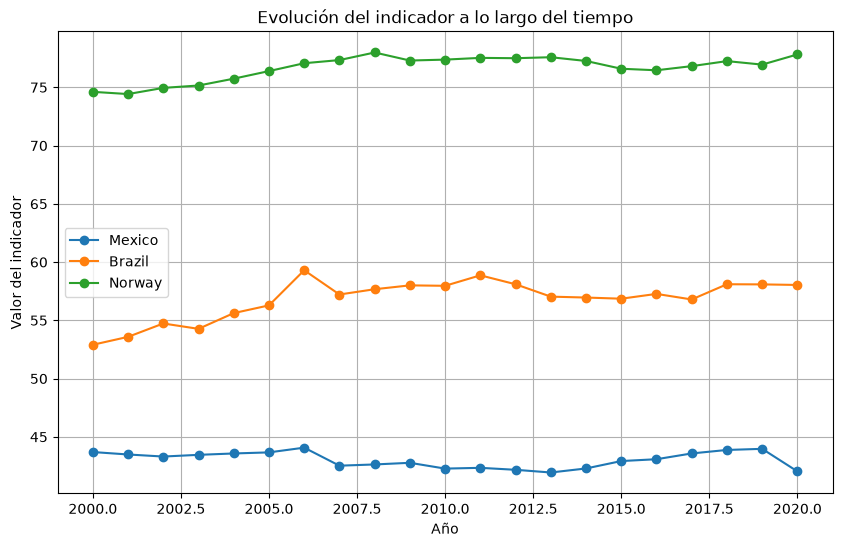

In [25]:
# Pregunta 8
# Tu codigo aqui

import matplotlib.pyplot as plt

paises_elegidos = ['Mexico', 'Brazil', 'Norway']

plt.figure(figsize=(10, 6))

for pais in paises_elegidos:
    df_temp = df_paises[df_paises['entity'] == pais].sort_values('year')
    plt.plot(df_temp['year'], df_temp['valor'], marker='o', label=pais)

plt.title('Evolución del indicador a lo largo del tiempo')
plt.xlabel('Año')
plt.ylabel('Valor del indicador')
plt.legend()
plt.grid(True)
plt.show()


**Interpretación:**

En la gráfica puse a México, Brasil y Noruega para comparar. Se ve súper claro que Noruega siempre ha estado muy por encima de los otros dos a lo largo de todos estos años, marcando mucha diferencia. Por otro lado, México y Brasil andan mucho más parejos en la parte de abajo, aunque se ven algunas subidas y bajadas leves año con año.

### Pregunta 9 — Visualización integradora

Crea dos gráficas de barras (horizontales o verticales) con el Top 10 de países según tu indicador en la primera consulta el año de tu nacimiento, y en la segunda el año 2023, ordenados de mayor a menor.  Qué movimientos hubo en ambas gráficas?
Agrega título y etiquetas de ejes.

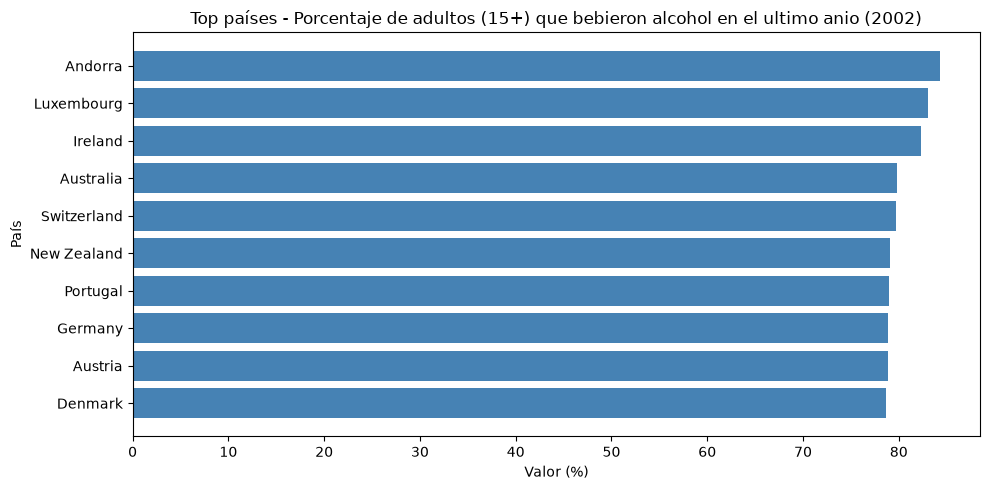

In [19]:
# Pregunta 9
# Tu codigo aqui
df_paises = df[df[config["filtro_paises"]].notnull()]

anio_consultado = 2002

top = (
    df_paises[df_paises['year'] == anio_consultado]
    .sort_values('valor', ascending=False)
    .head(10)
)
# Grafica de barras horizontales
plt.figure(figsize=(10, 5))
plt.barh(top['entity'], top['valor'], color='steelblue')

plt.xlabel(f"Valor ({config['unidad']})")
plt.ylabel("País")
plt.title(f"Top países - {config['descripcion']} ({anio_consultado})")

plt.gca().invert_yaxis()  # para que el país con el valor mas alto quede arriba
plt.tight_layout()
plt.show()


**Interpretación:**

En la gráfica del 2002 se ve que el top 10 con mayor porcentaje está dominado casi por puro país de Europa. Andorra está en el primer lugar, seguido muy de cerca por Luxemburgo e Irlanda. En general, todos los países de esta lista andan súper parejos y con niveles muy altos, rondando entre el 80% y 85%.

## 5. Conclusión general

En 5 - 10 líneas, resume qué aprendiste sobre el dataset que te tocó trabajar: ¿qué
patrones encontraste?, ¿qué limitaciones tiene la información (por ejemplo, valores
absolutos sin normalizar por población, datos faltantes, etc.)?, ¿qué harías distinto si
tuvieras más tiempo?

Trabajar con este dataset me permitió ver patrones muy claros sobre el porcentaje de adultos que consumen alcohol a nivel mundial. El patrón más evidente es que los países europeos como Andorra, Luxemburgo o Noruega siempre dominan los primeros lugares con niveles altísimos, mientras que países como Kuwait o Comoras están casi en cero, lo que explica por qué hay tanta variación y dispersión en los datos a nivel global. En cuanto a las limitaciones, aunque el dataset estaba súper limpio y no tuvimos que lidiar con nulos, el indicador es solo un porcentaje general; no nos dice qué tanta cantidad bebe la gente, ni toma en cuenta factores culturales por los que la gente podría mentir en las encuestas. Si tuviera más tiempo, cruzaría estos datos con otra información como el nivel económico del país, su religión o el clima para entender exactamente por qué existen diferencias tan extremas entre un continente y otro.

## 6. Entrega

1. Verifica que el notebook corra completo de arriba hacia abajo sin errores (`Kernel > Restart & Run All`).
2. Guarda el archivo con el nombre: `apellido_nombre_examen_parcial1.ipynb`.
3. Súbelo al repositorio de GitHub del curso, en una carpeta para este examen.
4. Comparte el link de tu repo y envia una copia del notebook por teams.
